# Logistic regression và softmax

Một bộ lọc thư rác nhận email “Chúc mừng! Bạn đã trúng iPhone, bấm vào đây để nhận”. Nó không cần biết chắc đây là spam. Điều nó cần là một con số kiểu “xác suất spam là 0.97”, để người dùng tự quyết định chặn từ mức nào. Linear regression của bài 2.1 cho ra một số thực bất kỳ, không phải xác suất. Bài này sửa đúng chỗ đó: giữ phần tuyến tính, nhưng ép đầu ra về khoảng $(0, 1)$ và học bằng một hàm mất mát hợp với xác suất. Kết quả là logistic regression, mô hình phân loại được dùng nhiều nhất trong thực tế và cũng chính là một neuron của mạng neural ở chương sau.

> **Mục tiêu**
>
> - Biết vì sao linear regression không dùng cho phân loại.
> - Viết logistic regression bằng NumPy và so với scikit-learn.
> - Chọn ngưỡng quyết định khác 0.5 khi cần.
> - Dùng softmax cho bài nhiều lớp.

## Dữ liệu: lọc thư rác

Mỗi email được mô tả bằng hai con số: số đường link và số từ quảng cáo như “miễn phí”, “trúng thưởng”, “khuyến mãi”. Nhãn là $1$ nếu là spam, $0$ nếu là thư thường. Giống bài 2.1, ta tự sinh dữ liệu từ một quy luật đã biết để sau này đối chiếu xem mô hình học được gì. Quy luật dùng hàm sigmoid, sẽ được giải thích ngay ở mục sau; lúc này chỉ cần biết email càng nhiều link và từ quảng cáo thì càng dễ là spam.

In [ ]:
import numpy as np

rng = np.random.default_rng(20)
n = 400
links = rng.poisson(2.0, n)                           # số đường link
kw = rng.poisson(1.5, n)                              # số từ quảng cáo
z_true = 1.1 * links + 0.9 * kw - 4.5                 # quy luật thật, mô hình không được biết
y = (rng.random(n) < 1 / (1 + np.exp(-z_true))).astype(float)   # 1 = spam

X = np.column_stack([links, kw]).astype(float)        # (400, 2)
X_tr, X_te, y_tr, y_te = X[:300], X[300:], y[:300], y[300:]
print(X_tr.shape, X_te.shape, " tỉ lệ spam:", y.mean())
print(X[:4], y[:4])

(300, 2) (100, 2)  tỉ lệ spam: 0.3125
[[1. 1.]
 [0. 0.]
 [2. 0.]
 [0. 3.]] [0. 0. 0. 0.]


Khoảng một phần ba số email là spam. 300 email đầu dùng để học, 100 email sau để kiểm tra.

## Vì sao không dùng linear regression?

Cách nghĩ đầu tiên: nhãn là số $0$ và $1$, vậy cứ chạy linear regression rồi coi đầu ra là xác suất.

In [ ]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression().fit(X_tr, y_tr)
p_lin = lin.predict(X_tr)
print("dự đoán nhỏ nhất:", p_lin.min().round(2), " lớn nhất:", p_lin.max().round(2))
print("số email có 'xác suất' ngoài [0, 1]:", np.sum((p_lin < 0) | (p_lin > 1)))

dự đoán nhỏ nhất: -0.2  lớn nhất: 1.34
số email có 'xác suất' ngoài [0, 1]: 54


Vấn đề thứ nhất hiện ngay trong output: một phần đáng kể dự đoán nằm ngoài $[0, 1]$. “Xác suất $-0.2$” không có nghĩa gì.

Vấn đề thứ hai nghiêm trọng hơn. Để dễ nhìn, tạm chỉ dùng số link. Linear regression cho một đường thẳng; email được coi là spam khi đường thẳng vượt $0.5$, tức số link vượt một ngưỡng nào đó. Giờ thêm vào tập train 20 email “siêu spam” có từ 15 đến 24 link. Những email này rõ ràng là spam, phân loại chúng chẳng khó gì, nên lẽ ra chúng không được làm thay đổi ranh giới.

In [ ]:
def link_threshold(model):
    """Số link tại đó đường thẳng cắt mức 0.5."""
    return (0.5 - model.intercept_) / model.coef_[0]

def accuracy_at(t):
    """Accuracy trên tập test khi coi email có từ t link trở lên là spam."""
    return np.mean((X_te[:, 0] >= t) == y_te)

L_tr = X_tr[:, :1]                                    # chỉ số link, shape (300, 1)
extra = np.repeat(np.arange(15, 25), 2)[:, None]      # 20 email siêu spam
L_more, y_more = np.vstack([L_tr, extra]), np.append(y_tr, np.ones(20))

for name, L, yy in [("300 email gốc    ", L_tr, y_tr), ("thêm 20 siêu spam", L_more, y_more)]:
    t = link_threshold(LinearRegression().fit(L, yy))
    print(f"{name}: ngưỡng = {t:.2f} link   accuracy test = {accuracy_at(t):.2f}")

300 email gốc    : ngưỡng = 3.07 link   accuracy test = 0.78
thêm 20 siêu spam: ngưỡng = 6.00 link   accuracy test = 0.68


Ngưỡng nhảy từ khoảng 3 link lên 6 link, và accuracy trên tập test tụt 10 điểm phần trăm. Lý do nằm ở hàm mất mát bình phương: email 24 link có nhãn $1$ nhưng đường thẳng dự đoán cho nó một số lớn hơn $1$ nhiều, nên bị tính là “sai nặng”. Để giảm cái sai vô lý đó, đường thẳng phải thoải xuống, kéo theo ngưỡng dịch sang phải. Mô hình bị phạt vì quá chắc chắn ở chỗ đúng.



Hai vấn đề có chung một gốc: đầu ra không bị chặn trong $(0, 1)$, và hàm mất mát không hợp với xác suất. Hai mục tiếp theo sửa lần lượt từng cái.

**Hỏi nhanh.** Thêm vào train 20 email có từ 15 đến 24 link, email nào cũng là spam thật. Vì sao ngưỡng của linear regression lại dịch từ khoảng 3 link lên 6 link?

- A. Email dễ, đã đúng nhãn, vẫn bị phạt vì dự đoán vượt quá 1
- B. Tỉ lệ spam trong train tăng nên ngưỡng phải tăng theo
- C. 20 email ấy thật ra bị gán nhãn sai nên làm hỏng mô hình
- D. Mô hình bị overfit vì có thêm mẫu ở vùng xa

<details><summary>Đáp án</summary>

A. Email dễ, đã đúng nhãn, vẫn bị phạt vì dự đoán vượt quá 1

Với email 24 link, đường thẳng cũ dự đoán một số lớn hơn 1 nhiều, và hàm bình phương tính đó là lỗi nặng dù email đã được phân loại đúng. Để giảm cái lỗi vô lý ấy, đường thẳng thoải xuống và ngưỡng dịch sang phải. Riêng việc có thêm spam thì sẽ kéo đường lên, làm ngưỡng thấp đi chứ không cao lên. Còn mô hình chỉ có hai tham số thì không có chỗ để overfit.

</details>

## Sigmoid và log-odds

Giữ phần tuyến tính $z = \mathbf{w}^\top\mathbf{x} + b$ như cũ, rồi ép nó về khoảng $(0, 1)$ bằng hàm sigmoid:

$$p = P(y = 1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}.$$



Sigmoid nhận mọi số thực và trả về một số trong $(0, 1)$. $z = 0$ cho $p = 0.5$; $z = 3$ cho $p \approx 0.95$; $z = -3$ cho $p \approx 0.05$. Đi xa khỏi 0 thì đường cong phẳng dần: tăng $z$ từ 10 lên 20 gần như không đổi $p$. Tên có chữ “hồi quy” vì mô hình hồi quy ra một xác suất, nhưng việc của nó là phân loại: cắt xác suất ở một ngưỡng là có nhãn.

Để hiểu $z$ là gì, giải ngược phương trình trên theo $z$:

$$z = \log \frac{p}{1 - p}.$$

Tỉ số $\frac{p}{1-p}$ gọi là odds, cách nói “mấy ăn một” quen thuộc trong cá cược: $p = 0.75$ thì odds là $3$, nghĩa là khả năng spam gấp 3 khả năng không spam. $z$ là log của odds, gọi là log-odds hay logit. Vậy logistic regression là một mô hình tuyến tính, nhưng tuyến tính cho log-odds chứ không cho xác suất. Đi ngược lại cũng dễ: $z = \ln 3$ cho odds 3, tức $p = 3/4$. Muốn lúc đầu mô hình đoán khoảng $0.01$ cho bài chỉ có 1% mẫu dương thì đặt bias bằng $\ln(0.01/0.99) \approx -4.6$.

Hệ quả trực tiếp: tăng $x_j$ thêm một đơn vị thì $z$ tăng $w_j$, nên odds nhân thêm $e^{w_j}$. Bài báo y khoa hay viết “hút thuốc làm odds mắc bệnh tăng gấp 3” chính là đọc hệ số của logistic regression theo cách này.

**Hỏi nhanh.** Mô hình cho một email $p = 0.8$. Odds spam của email ấy bằng bao nhiêu?

- A. $4$
- B. $0.8$
- C. $0.2$
- D. $1.25$

<details><summary>Đáp án</summary>

A. $4$

Odds là $p/(1-p) = 0.8/0.2 = 4$, tức khả năng là spam gấp bốn lần khả năng không phải spam. $1.25$ là $1/0.8$, nhầm odds với nghịch đảo của xác suất.

</details>

## Ranh giới quyết định

Muốn ra nhãn thì cắt xác suất ở một ngưỡng, mặc định là $0.5$. Vì $\sigma(z) \ge 0.5$ khi và chỉ khi $z \ge 0$, ranh giới giữa hai lớp là tập điểm có

$$\mathbf{w}^\top\mathbf{x} + b = 0.$$

Với hai đặc trưng, đó là một đường thẳng; với $d$ đặc trưng, một siêu phẳng. Sigmoid chỉ quyết định xác suất thay đổi nhanh hay chậm khi đi xuyên qua ranh giới, không làm ranh giới cong đi. Logistic regression vì vậy vẫn là một bộ phân loại tuyến tính. Muốn ranh giới cong thì làm như bài 2.1: thêm đặc trưng $x_1^2, x_2^2, x_1x_2$, khi đó ranh giới thẳng trong không gian đặc trưng mới thành đường cong trong mặt phẳng cũ. Chẳng hạn thêm một cột $x_1^2 + x_2^2$ thì ranh giới là đường tròn, hoặc vẫn là đường thẳng nếu hệ số của cột đó bằng 0.



Với một đặc trưng, ranh giới là một điểm: $x = -b/w$. Nhân cả $\mathbf{w}$ và $b$ với một số dương không đổi dấu của $z$, nên không đổi nhãn nào; chỉ xác suất dốc hơn hay thoải hơn quanh ranh giới. Khoảng cách từ điểm $\mathbf{x}$ tới ranh giới là $|\mathbf{w}^\top\mathbf{x} + b| / \lVert\mathbf{w}\rVert$. Lặp lại thí nghiệm 20 email siêu spam, lần này bằng logistic regression của scikit-learn. Tham số `C=np.inf` tắt khoản phạt của bài 2.2 để so cho công bằng với linear regression không phạt; mục sau sẽ nói kỹ hơn.

In [ ]:
from sklearn.linear_model import LogisticRegression

for name, L, yy in [("300 email gốc    ", L_tr, y_tr), ("thêm 20 siêu spam", L_more, y_more)]:
    m = LogisticRegression(C=np.inf).fit(L, yy)
    t = -m.intercept_[0] / m.coef_[0, 0]
    print(f"{name}: ngưỡng = {t:.2f} link   accuracy test = {accuracy_at(t):.2f}")

300 email gốc    : ngưỡng = 3.01 link   accuracy test = 0.78
thêm 20 siêu spam: ngưỡng = 3.01 link   accuracy test = 0.78


Ngưỡng không nhúc nhích, ít nhất đến hai chữ số thập phân. Với email 24 link, mô hình đã cho $p$ rất gần $1$; đúng nhãn và đúng tự tin thì gần như không bị phạt, nên những email này không kéo ranh giới đi đâu cả. Lý do nằm ở hàm mất mát của mục tiếp theo.

**Hỏi nhanh.** Logistic regression một feature có $w = 2$, $b = -6$. Ranh giới quyết định nằm ở đâu?

- A. $x = -3$
- B. $x = 6$
- C. $x = 0.5$
- D. $x = 3$

<details><summary>Đáp án</summary>

D. $x = 3$

Ranh giới là nơi $z = 2x - 6 = 0$, tức $x = 3$. Tại đó $p = \sigma(0) = 0.5$.

</details>

## Hàm mất mát: cross-entropy

Mô hình gán xác suất $p_i$ cho nhãn $1$ và $1 - p_i$ cho nhãn $0$. Một cách tự nhiên để chấm điểm là hỏi: mô hình gán bao nhiêu xác suất cho đúng cái nhãn đã xảy ra? Với một mẫu, con số đó là $p_i$ nếu $y_i = 1$ và $1 - p_i$ nếu $y_i = 0$, viết gọn là $p_i^{y_i}(1-p_i)^{1-y_i}$. Coi các email độc lập, xác suất cho cả tập dữ liệu là tích của chúng. Chọn tham số làm tích này lớn nhất gọi là maximum likelihood.

Tích của hàng trăm số nhỏ hơn 1 rất khó làm việc, nên ta lấy log để biến tích thành tổng, đổi dấu để thành bài toán cực tiểu, rồi chia cho $n$. Kết quả là binary cross-entropy, còn gọi là log loss:

$$J(\mathbf{w}, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[\,y_i \log p_i + (1 - y_i)\log(1 - p_i)\,\Big].$$

Trong mỗi số hạng chỉ một trong hai phần còn lại: với email spam là $-\log p_i$, với thư thường là $-\log(1 - p_i)$. Nhìn vào một email spam thật: đoán $p = 0.99$ mất $0.01$; đoán $p = 0.5$ mất $0.69$; đoán $p = 0.01$ mất $4.6$. Khi $p \to 0$, loss tăng vô hạn. Cross-entropy phạt rất nặng sự tự tin sai, và gần như không phạt sự tự tin đúng. Đây chính là lý do 20 email siêu spam không kéo được ranh giới. Với thư thường mà mô hình đoán $p = 0.9$, loss là $-\log 0.1 \approx 2.30$. Nhưng mọi email vẫn góp một khoản dương, dù nhỏ, nên ranh giới phụ thuộc vào tất cả các điểm chứ không chỉ những điểm gần nó.

Tại sao không giữ hàm bình phương $(p - y)^2$ cho quen? Hãy nhìn gradient theo $z$. Với một email spam mà mô hình đang đoán $p = 0.01$, tức sai rất nặng:

- Bình phương: $\frac{\partial}{\partial z}(p - 1)^2 = 2(p - 1)\,p(1 - p) \approx -0.0196$.
- Cross-entropy: $\frac{\partial}{\partial z}\big(-\log p\big) = p - 1 = -0.99$.

Gradient của hàm bình phương nhỏ hơn 50 lần, đúng ở chỗ mô hình cần sửa nhiều nhất. Thừa số $p(1-p)$ đến từ đạo hàm của sigmoid và gần bằng 0 ở hai đầu, nơi đường cong phẳng. Cross-entropy có $\log$ triệt tiêu đúng thừa số đó. Thêm nữa, hàm bình phương ghép với sigmoid không còn lồi, còn cross-entropy thì lồi: không có cực tiểu địa phương nào để mắc kẹt.



**Hỏi nhanh.** Với $p = \sigma(z)$, nếu dùng bình phương sai số thay cho cross-entropy, thì khi mô hình rất tự tin mà sai, chuyện gì xảy ra?

- A. Gradient theo $z$ vẫn luôn bằng $p - y$
- B. Bình phương sai số không tính được với nhãn 0 và 1
- C. Gradient theo $z$ có thể rất nhỏ, do thừa số $p(1-p)$
- D. Không có gradient, vì sigmoid không có đạo hàm

<details><summary>Đáp án</summary>

C. Gradient theo $z$ có thể rất nhỏ, do thừa số $p(1-p)$

Bình phương sai số vẫn tính được và vẫn lấy đạo hàm được. Nhưng đạo hàm của sigmoid gần bằng 0 ở hai đầu, nên đúng lúc mô hình tự tin mà sai thì bước cập nhật lại rất nhỏ. Ghép cross-entropy với sigmoid thì thừa số ấy triệt tiêu, gradient chỉ còn $p - y$.

</details>

## Gradient và tự cài bằng NumPy

Đạo hàm của sigmoid có dạng đẹp: $\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big) = p(1 - p)$. Với một mẫu, loss là $\ell = -\big[y\log p + (1-y)\log(1-p)\big]$. Theo quy tắc chuỗi:

$$\frac{\partial \ell}{\partial z} = \underbrace{\left(-\frac{y}{p} + \frac{1-y}{1-p}\right)}_{\partial \ell / \partial p} \cdot \underbrace{p(1-p)}_{\partial p / \partial z} = -y(1-p) + (1-y)p = p - y.$$

Mọi phân số triệt tiêu, chỉ còn lại “xác suất đoán trừ nhãn thật”. Vì $z = \mathbf{w}^\top\mathbf{x} + b$, nhân thêm $\mathbf{x}$ để có đạo hàm theo $\mathbf{w}$, rồi lấy trung bình trên cả tập:

$$\nabla_{\mathbf{w}} J = \frac{1}{n} X^\top(\mathbf{p} - \mathbf{y}), \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i}(p_i - y_i).$$

So với linear regression ở bài 2.1, công thức giống hệt, chỉ thay $\hat{\mathbf{y}}$ bằng $\mathbf{p}$ và không có hệ số 2. Sự trùng hợp này không phải tình cờ: cả hai thuộc cùng một họ mô hình (generalized linear model), và ở đó gradient luôn có dạng “dự đoán trừ thực tế, nhân với đặc trưng”.

Bảng shape cho 300 email train với 2 đặc trưng:

| Đại lượng | Biểu thức | Shape |
|---|---|---|
| Đặc trưng | `X` | $(300, 2)$ |
| Tham số | `w`, `b` | $(2,)$, số |
| Điểm tuyến tính | `z = X @ w + b` | $(300,)$ |
| Xác suất | `p = sigmoid(z)` | $(300,)$ |
| Sai lệch | `p - y` | $(300,)$ |
| Gradient theo `w` | `X.T @ (p - y) / n` | $(2,)$ |

Cài đặt theo đúng cách của bài 2.1, gộp $(\mathbf{w}, b)$ vào một vector `theta`:

In [ ]:
def sigmoid(z):
    # sigmoid(z) = exp(-log(1 + exp(-z))), tính ổn định
    return np.exp(-np.logaddexp(0., -z))

def loss(theta, X, y):
    logits = X @ theta[:-1] + theta[-1]
    # cross-entropy tính thẳng từ logits: không tràn số, không cần kẹp
    return np.mean(np.logaddexp(0., logits) - y * logits)

def grad(theta, X, y):
    r = sigmoid(X @ theta[:-1] + theta[-1]) - y       # p − y, shape (n,)
    return np.append(X.T @ r / len(y), r.mean())

Loss được tính thẳng từ logits bằng `logaddexp`, nên không tràn số và không cần kẹp xác suất. Nếu kẹp xác suất ngay trong loss dùng để học, gradient $p - y$ sẽ không còn khớp ở vùng bị kẹp. Trước khi huấn luyện, kiểm gradient bằng sai phân trung tâm như bài 2.1, bước rẻ nhất để bắt lỗi dấu hoặc lỗi chia $n$:

In [ ]:
def numerical_grad(f, theta, h=1e-5):
    g = np.zeros_like(theta)
    for j in range(len(theta)):
        e = np.zeros_like(theta)
        e[j] = h
        g[j] = (f(theta + e) - f(theta - e)) / (2 * h)
    return g

def rel_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))

theta0 = np.random.default_rng(1).normal(size=3)
num = numerical_grad(lambda t: loss(t, X_tr, y_tr), theta0)
print(f"sai số tương đối: {rel_error(grad(theta0, X_tr, y_tr), num):.1e}")

sai số tương đối: 5.8e-12


Sai số cỡ $10^{-12}$: gradient đúng. Giờ chạy gradient descent. Hai đặc trưng đều là số đếm nhỏ, cùng thang đo, nên ở đây không cần chuẩn hóa.

In [ ]:
theta = np.zeros(3)
history = []
for epoch in range(5000):
    history.append(loss(theta, X_tr, y_tr))
    theta -= 0.5 * grad(theta, X_tr, y_tr)

print("w =", theta[:2].round(3), "  b =", theta[2].round(3))
print("loss ban đầu:", round(history[0], 4), "  sau 5000 vòng:", round(history[-1], 4))

w = [1.124 0.947]   b = -4.73
loss ban đầu: 0.6931   sau 5000 vòng: 0.3995


Loss ban đầu là $0.6931 = \log 2$, không phải ngẫu nhiên: với `theta` bằng 0, mọi email có $p = 0.5$ và mỗi email mất $-\log 0.5$. Đây là một mốc nên nhớ để kiểm code: bài hai lớp khởi tạo bằng 0 thì loss ban đầu phải là $\log 2$ (dùng class weight thì mốc này đổi).

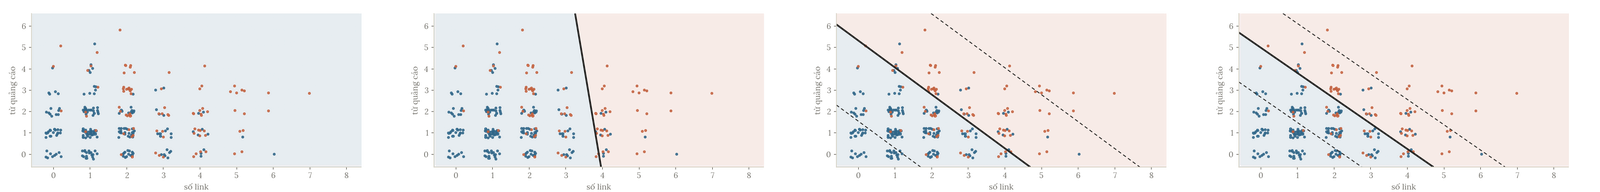

Tham số học được nằm gần quy luật thật $(1.1,\ 0.9,\ -4.5)$; phần lệch là do chỉ có 300 email. Đối chiếu với scikit-learn:

In [ ]:
model = LogisticRegression(C=np.inf).fit(X_tr, y_tr)
print("scikit-learn: w =", model.coef_[0].round(3), "  b =", model.intercept_.round(3))
print("trùng gradient descent:", np.allclose(theta, np.append(model.coef_[0], model.intercept_), atol=1e-3))

scikit-learn: w = [1.124 0.947]   b = [-4.73]
trùng gradient descent: True


Hai cách cho cùng một nghiệm. scikit-learn không dùng gradient descent mà dùng L-BFGS, một phương pháp dùng thêm thông tin độ cong nên hội tụ trong vài chục bước thay vì vài nghìn. Khác với linear regression, ở đây không có nghiệm đóng: đặt gradient bằng 0 cho một hệ phương trình chứa sigmoid, không giải ra được bằng biến đổi đại số.

> **Về tham số C**
>
> `LogisticRegression` mặc định có phạt L2 với `C=1.0`, trong đó `C` tỉ lệ nghịch với $\lambda$ của bài 2.2. Ở trên ta dùng `C=np.inf` để tắt phạt và so được với code tự viết. Trong thực tế nên giữ phạt: khi dữ liệu tách được hoàn toàn bằng một đường thẳng, logistic regression không phạt sẽ đẩy trọng số lên vô hạn để mọi $p$ tiến về đúng 0 hoặc 1, và thuật toán không bao giờ dừng ở một nghiệm hữu hạn.

**Hỏi nhanh.** Khởi tạo mọi tham số bằng 0 cho một bài phân loại hai lớp. Cross-entropy lúc đầu bằng bao nhiêu?

- A. $0$
- B. $0.5$
- C. $\log 2 \approx 0.693$
- D. Không xác định được

<details><summary>Đáp án</summary>

C. $\log 2 \approx 0.693$

Mọi $z$ đều bằng 0 nên mọi $p$ đều bằng 0.5, và mẫu nào cũng mất $-\log 0.5 = \log 2$, bất kể nhãn là gì.

</details>

## Đọc hệ số qua odds

Hệ số của logistic regression không đọc được như linear regression, kiểu “thêm một link thì xác suất tăng bao nhiêu”. Cách đọc đúng là qua odds, như mục trước đã nói.

In [ ]:
w = model.coef_[0]
print("thêm 1 link: odds nhân", np.exp(w[0]).round(2), "  thêm 1 từ quảng cáo: odds nhân", np.exp(w[1]).round(2))

emails = np.array([[1, 1], [2, 1], [7, 1], [8, 1]])     # (số link, số từ quảng cáo)
print("P(spam):", model.predict_proba(emails)[:, 1].round(3))

thêm 1 link: odds nhân 3.08   thêm 1 từ quảng cáo: odds nhân 2.58
P(spam): [0.065 0.177 0.983 0.995]


Mỗi link thêm vào nhân odds spam lên khoảng 3 lần, bất kể email đang ở đâu. Nhưng xác suất thì không tăng đều. Đi từ 1 lên 2 link, xác suất tăng khoảng 0.11; đi từ 7 lên 8 link, khi email đã gần như chắc là spam, xác suất chỉ nhích thêm khoảng 0.01 vì không thể vượt quá 1. Odds nhân đều, xác suất bão hòa. Muốn so độ quan trọng giữa các đặc trưng có đơn vị khác nhau thì chuẩn hóa trước, giống bài 2.2.



**Hỏi nhanh.** Một email đang có $p = 0.5$. Hệ số của “số link” là $w = \ln 3$. Thêm một link thì $p$ thành bao nhiêu?

- A. $1.5$
- B. $0.83$
- C. $0.6$
- D. $0.75$

<details><summary>Đáp án</summary>

D. $0.75$

Odds ban đầu bằng 1, nhân thêm $e^{\ln 3} = 3$ thành 3, nên $p = 3/(1+3) = 0.75$. Nhân thẳng xác suất với 3 thì ra $1.5$, không còn là xác suất.

</details>

## Ngưỡng quyết định

> **Chọn ngưỡng trên validation**
>
> Tập gọi là test trong ví dụ nhỏ dưới đây được dùng để minh họa nhiều ngưỡng. Nếu dùng bảng đó để chọn ngưỡng, nó đã đóng vai trò validation. Trong một bài thật, chọn ngưỡng theo chi phí hoặc metric trên validation và chỉ chấm test để riêng sau khi chốt lựa chọn.

Ngưỡng $0.5$ hợp lý khi hai loại sai có giá như nhau. Với bộ lọc thư rác thì không: để lọt một email spam chỉ hơi phiền, còn chặn nhầm một email thật (thư mời nhập học, kết quả thi) có thể rất đắt. Xem ngưỡng thay đổi điều gì trên 100 email test:

In [ ]:
p_te = model.predict_proba(X_te)[:, 1]
print("predict trùng p > 0.5:", np.array_equal(model.predict(X_te), (p_te > 0.5).astype(float)))
for t in [0.3, 0.5, 0.9]:
    block = p_te >= t
    print(f"ngưỡng {t}: chặn đúng {np.sum(block & (y_te == 1)):>2} spam, "
          f"chặn nhầm {np.sum(block & (y_te == 0)):>2} thư thật, lọt {np.sum(~block & (y_te == 1)):>2} spam")
print("accuracy:", model.score(X_te, y_te), "  luôn đoán 'không spam':", np.mean(y_te == 0))

predict trùng p > 0.5: True
ngưỡng 0.3: chặn đúng 30 spam, chặn nhầm 21 thư thật, lọt  3 spam
ngưỡng 0.5: chặn đúng 25 spam, chặn nhầm  7 thư thật, lọt  8 spam
ngưỡng 0.9: chặn đúng  4 spam, chặn nhầm  0 thư thật, lọt 29 spam
accuracy: 0.85   luôn đoán 'không spam': 0.67


Dòng đầu xác nhận `predict` chính là cắt $p > 0.5$ (đúng bằng $0.5$ thì scikit-learn chọn lớp 0). Hạ ngưỡng thì chặn được nhiều spam hơn nhưng chặn nhầm nhiều thư thật hơn; nâng ngưỡng thì ngược lại. Không có ngưỡng nào tốt nhất cho mọi bài: ngưỡng là quyết định nghiệp vụ, chọn theo cái giá của từng loại sai. Mô hình chỉ cung cấp xác suất. Bài 1.5 có các thước đo cho đúng sự đánh đổi này (precision, recall, đường ROC).



Dòng cuối là một lời nhắc khác. Một “mô hình” luôn đoán “không spam” đã được accuracy khoảng $0.67$, vì hai phần ba số email là thư thường. Accuracy của mô hình thật phải được so với mốc đó, không phải với $0$. Dữ liệu càng lệch thì mốc này càng cao: nếu chỉ 1% email là spam, đoán bừa “không spam” đã có accuracy $0.99$.

Khi đề bài chấm bằng log loss, cái cần nộp là xác suất. Mốc tương ứng là đoán cho mọi email cùng một xác suất bằng tỉ lệ spam của tập train:

In [ ]:
from sklearn.metrics import log_loss

base = np.full(len(y_te), y_tr.mean())
print("log loss mốc:", round(log_loss(y_te, base), 3), "  mô hình:", round(log_loss(y_te, p_te), 3))

log loss mốc: 0.635   mô hình: 0.371


**Hỏi nhanh.** Với bộ lọc thư rác, chặn nhầm một thư thật tốn kém hơn nhiều so với để lọt một thư spam. Ta nên chỉnh ngưỡng thế nào?

- A. Hạ ngưỡng xuống $0.3$ để chặn được nhiều spam hơn
- B. Nâng ngưỡng lên, và chọn mức cụ thể trên validation
- C. Giữ $0.5$, vì đó là ngưỡng chuẩn của mô hình
- D. Huấn luyện thêm nhiều vòng cho mô hình chắc hơn

<details><summary>Đáp án</summary>

B. Nâng ngưỡng lên, và chọn mức cụ thể trên validation

Ngưỡng cao nghĩa là chỉ chặn khi rất chắc chắn. Như vậy ít chặn nhầm thư thật hơn, đổi lại lọt nhiều spam hơn. Mức cụ thể, chẳng hạn $0.9$, phải chọn theo chi phí của hai loại sai trên validation. Huấn luyện thêm không thay đổi được sự đánh đổi này.

</details>

## Nhiều lớp: softmax regression

Nhận dạng chữ số viết tay có 10 lớp, từ 0 đến 9. Mở rộng tự nhiên: mỗi lớp $k$ có vector trọng số $\mathbf{w}_k$ và bias $b_k$ riêng, cho một điểm $z_k = \mathbf{w}_k^\top\mathbf{x} + b_k$ (gọi chung là logits). Hàm softmax biến $K$ điểm thành một phân phối xác suất:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}.$$

Mọi $p_k$ dương và cộng lại bằng 1. Lớp có điểm cao nhất có xác suất cao nhất, nhưng các lớp khác không bị đẩy về đúng 0, nên “max” mềm hơn, đúng như tên gọi. Với $K = 2$, $p_1 = \frac{1}{1 + e^{-(z_1 - z_2)}} = \sigma(z_1 - z_2)$: softmax hai lớp chính là logistic regression trên hiệu hai điểm. Softmax luôn chia hết xác suất cho các lớp đã biết: đưa ảnh một chiếc ô tô vào mô hình chó, mèo, chim thì nó vẫn chọn một trong ba, có khi rất chắc.

Hàm mất mát vẫn là cross-entropy: $\ell = -\log p_{y}$, trừ log xác suất của lớp đúng. Gradient theo logits cũng giữ dạng quen thuộc:

$$\frac{\partial \ell}{\partial \mathbf{z}} = \mathbf{p} - \mathbf{e}_y,$$

trong đó $\mathbf{e}_y$ là vector one-hot của nhãn thật. Mô hình đẩy xác suất của lớp đúng lên và của các lớp khác xuống, đúng bằng lượng đang chênh. Mỗi thành phần của $\mathbf{p} - \mathbf{e}_y$ nằm trong $[-1, 1]$: âm ở lớp đúng, dương ở các lớp khác.

| Đại lượng | Biểu thức | Shape (1300 ảnh, 64 điểm ảnh, 10 lớp) |
|---|---|---|
| Ảnh | `X` | $(1300, 64)$ |
| Trọng số | `W`, `b` | $(64, 10)$, $(10,)$ |
| Logits | `Z = X @ W + b` | $(1300, 10)$ |
| Xác suất | `P = softmax(Z)` | $(1300, 10)$, mỗi hàng cộng bằng 1 |
| Nhãn one-hot | `Y` | $(1300, 10)$ |
| Gradient theo `W` | `X.T @ (P - Y) / n` | $(64, 10)$ |

Cài softmax có một cái bẫy. $e^{1000}$ vượt quá số lớn nhất mà kiểu `float64` biểu diễn được, nên thành `inf`, và `inf / inf` là `nan`. Cách chữa dựa trên một nhận xét: cộng cùng một hằng số $c$ vào mọi $z_k$ không đổi softmax, vì $e^{c}$ xuất hiện ở cả tử lẫn mẫu và triệt tiêu. Chọn $c = -\max_k z_k$ thì số mũ lớn nhất là $0$, không bao giờ tràn. Cùng lý do, nhân mọi logit với một số dương giữ nguyên thứ tự nên giữ nguyên lớp dự đoán, chỉ làm phân phối nhọn hơn hay bẹt hơn.

In [ ]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()

def softmax(Z):
    Z = Z - Z.max(axis=-1, keepdims=True)             # trừ max từng hàng, kết quả không đổi
    E = np.exp(Z)
    return E / E.sum(axis=-1, keepdims=True)

z = np.array([2.0, 1.0, 0.0])
print(softmax(z).round(3))
print(softmax_naive(z + 1000), softmax(z + 1000).round(3))

[0.665 0.245 0.09 ]
[nan nan nan] [0.665 0.245 0.09 ]


Khi cần $\log p_k$ (để tính loss) thì đừng tính softmax rồi mới lấy log, vì $p_k$ rất nhỏ có thể làm tròn thành 0. Dùng thẳng log-sum-exp với cùng mẹo trừ max:

$$\log p_k = z_k - m - \log\sum_j e^{z_j - m}, \qquad m = \max_j z_j.$$

Thử trên bộ chữ số viết tay của scikit-learn: 1797 ảnh $8 \times 8$, mỗi điểm ảnh có giá trị từ 0 đến 16.

In [ ]:
from sklearn.datasets import load_digits

D, t = load_digits(return_X_y=True)
D = D / 16                                            # điểm ảnh về [0, 1]
idx = np.random.default_rng(0).permutation(len(t))
D, t = D[idx], t[idx]
D_tr, D_te, t_tr, t_te = D[:1300], D[1300:], t[:1300], t[1300:]
print(D_tr.shape, D_te.shape)

(1300, 64) (497, 64)


Huấn luyện bằng gradient descent. Để so được với `LogisticRegression()` mặc định (`C=1`), ta thêm đúng khoản phạt L2 mà nó dùng: hàm mất mát của scikit-learn là $C\sum_i \ell_i + \tfrac12\lVert W\rVert^2$, chia cho $Cn$ thì thành loss trung bình cộng $\tfrac{1}{2Cn}\lVert W\rVert^2$.

In [ ]:
n, K = len(t_tr), 10
Y = np.eye(K)[t_tr]                                   # one-hot, (1300, 10)
lam = 1 / (1.0 * n)                                   # khớp C = 1
W, b = np.zeros((D_tr.shape[1], K)), np.zeros(K)
for epoch in range(5000):
    G = (softmax(D_tr @ W + b) - Y) / n               # (1300, 10)
    W -= 2.0 * (D_tr.T @ G + lam * W)
    b -= 2.0 * G.sum(axis=0)

pred = np.argmax(D_te @ W + b, axis=1)
print("tự cài:       accuracy test =", round(np.mean(pred == t_te), 3))

sk = LogisticRegression(C=1.0, max_iter=1000).fit(D_tr, t_tr)
print("scikit-learn: accuracy test =", round(sk.score(D_te, t_te), 3))
print("nhãn trùng nhau:", np.mean(sk.predict(D_te) == pred),
      "  xác suất lệch lớn nhất:", np.abs(sk.predict_proba(D_te) - softmax(D_te @ W + b)).max().round(3))

tự cài:       accuracy test = 0.978
scikit-learn: accuracy test = 0.978
nhãn trùng nhau: 1.0   xác suất lệch lớn nhất: 0.032


Một mô hình tuyến tính đơn giản đã nhận đúng khoảng 98% chữ số. Hai cài đặt cho cùng nhãn trên mọi ảnh test; xác suất còn lệch nhau một chút vì gradient descent sau 5000 vòng vẫn chưa hội tụ hẳn, trong khi L-BFGS của scikit-learn đã tới nơi.

Mỗi cột của `W` có 64 số, xếp lại thành ảnh $8 \times 8$ thì đọc được mô hình đang “nhìn” gì. Điểm ảnh có trọng số dương là nơi nét mực làm tăng điểm của lớp đó, trọng số âm là nơi nét mực làm giảm điểm. Hình dưới không giống những chữ số mẫu: mô hình không học “chữ 0 trông thế nào” mà học “chỗ nào có mực thì phân biệt được 0 với chín lớp còn lại”.



**Hỏi nhanh.** Cộng thêm $100$ vào mọi logit $z_1, \dots, z_K$. Xác suất softmax thay đổi thế nào?

- A. Không thay đổi
- B. Lớp có logit lớn nhất tăng lên gần 1
- C. Mọi xác suất đều tăng lên
- D. Thành `nan`

<details><summary>Đáp án</summary>

A. Không thay đổi

$e^{100}$ xuất hiện ở cả tử và mẫu nên triệt tiêu nhau. Về toán thì xác suất không đổi. Về tính toán thì cách cài đặt ngây thơ có thể tràn số, nên ta trừ đi logit lớn nhất trước khi lấy mũ.

</details>

## Ví dụ tính tay

Một mẫu $x = 2$, nhãn $y = 1$, mô hình $w = 1$, $b = -1$.

- $z = 1 \cdot 2 - 1 = 1$, $p = \sigma(1) = \frac{1}{1 + e^{-1}} = 0.731$.
- Loss $= -\log 0.731 = 0.313$.
- Gradient theo $w$: $(p - y)\,x = (0.731 - 1)\cdot 2 = -0.538$. Gradient âm nghĩa là tăng $w$ sẽ giảm loss. Một bước gradient descent với learning rate $0.5$ cho $w = 1 + 0.5 \cdot 0.538 = 1.269$: mô hình tự tin hơn vào nhãn đúng.

Softmax với $\mathbf{z} = (2, 1, 0)$: trừ max được $(0, -1, -2)$; lấy mũ được $(1,\ 0.368,\ 0.135)$; tổng là $1.503$; chia ra được $\mathbf{p} = (0.665,\ 0.245,\ 0.090)$. Lớp đầu hơn lớp thứ hai 1 đơn vị logit, và xác suất gấp $e \approx 2.7$ lần. Nếu nhãn đúng là lớp thứ hai thì loss là $-\log 0.245 = 1.41$ và gradient theo logits là $\mathbf{p} - \mathbf{e}_2 = (0.665,\ -0.755,\ 0.090)$: kéo lớp đầu xuống, đẩy lớp thứ hai lên.



## Khi đi thi

- **Metric là log loss**: nộp `predict_proba`, kẹp xác suất trước khi nộp. Logistic regression cho xác suất khá đáng tin ngay từ đầu (well-calibrated), điều nhiều mô hình mạnh hơn không có.
- **Metric là F1 hoặc lớp hiếm**: huấn luyện xong, chọn ngưỡng trên tập validation thay vì để mặc định $0.5$ (bài 1.5). `class_weight="balanced"` là một cách khác để mô hình chú ý lớp hiếm.
- **Văn bản**: TF-IDF cộng logistic regression là baseline rất mạnh, chạy vài giây, nhiều mô hình lớn phải vất vả mới vượt được khi dữ liệu ít (bài 6.1).
- **Baseline đầu tiên cho mọi bài phân loại dữ liệu bảng**: `make_pipeline(StandardScaler(), LogisticRegression(C=...))`, dò `C` trên thang log.
- **Ghép mô hình**: logistic regression trên xác suất out-of-fold của các mô hình khác là tầng cuối an toàn khi stacking (bài 8.4).
- **Tự cài loss**: dùng log-sum-exp/logaddexp từ logits để tránh tràn và giữ gradient đúng objective. Khi chỉ có xác suất để chấm metric, clipping là một quy ước riêng cần ghi rõ.

## Tóm tắt

- Linear regression trên nhãn 0/1 cho “xác suất” ngoài $[0, 1]$ và bị những điểm dễ phân loại kéo lệch ranh giới.
- Logistic regression là mô hình tuyến tính cho log-odds: $p = \sigma(\mathbf{w}^\top\mathbf{x} + b)$. Mỗi đơn vị của $x_j$ nhân odds lên $e^{w_j}$. Ranh giới quyết định vẫn là đường thẳng.
- Học bằng cực tiểu cross-entropy, sinh ra từ maximum likelihood. Hàm lồi, gradient $\frac1n X^\top(\mathbf{p} - \mathbf{y})$ cùng dạng với linear regression; không có nghiệm đóng.
- Ngưỡng $0.5$ chỉ là mặc định; chọn ngưỡng theo cái giá của từng loại sai. So accuracy với mốc đoán lớp đông nhất.
- Softmax mở rộng ra $K$ lớp với gradient $\mathbf{p} - \mathbf{e}_y$; khi cài phải trừ max và kẹp xác suất.

## Kiểm tra cuối bài

Mười câu dưới đây bao quát cả bài. Làm hết rồi xem điểm; câu nào sai thì đọc lại mục tương ứng.

**Câu 1.** Bài phân loại hai lớp có ba feature: tuổi từ 18 đến 80, thu nhập từ 20 đến 500 triệu, và điểm tín dụng từ 300 đến 850. Logistic regression không chuẩn hóa đạt accuracy 72%, thêm `StandardScaler` thì đạt 84%. Vì sao?

- A. Chuẩn hóa loại bỏ các giá trị thu nhập bất thường, chống overfit nhóm giàu
- B. Chuẩn hóa đưa dữ liệu về quanh 0, vào vùng gần tuyến tính của sigmoid
- C. Cùng thang đo thì tối ưu hội tụ tốt, cột thu nhập không còn lấn át gradient
- D. Chuẩn hóa tăng learning rate cho feature ít biến thiên nhất

<details><summary>Đáp án</summary>

C. Cùng thang đo thì tối ưu hội tụ tốt, cột thu nhập không còn lấn át gradient

Cột thu nhập lớn hơn cột tuổi hàng triệu lần nên chi phối gradient. Thung lũng loss hẹp như ở bài 2.1, và quá trình tối ưu dừng trước khi tới đáy. `LogisticRegression` mặc định còn phạt L2, mà khoản phạt chỉ công bằng khi các feature cùng thang đo (bài 2.2). Chuẩn hóa không xóa được giá trị bất thường. Vùng gần tuyến tính của sigmoid phụ thuộc vào $z = \mathbf w^\top\mathbf x + b$, không phụ thuộc riêng vào $\mathbf x$.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 305](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=117)

</details>

**Câu 2.** Hệ số của một feature là $w_j = 0.7$. Tăng feature ấy thêm 1 đơn vị, giữ nguyên các feature khác. Điều gì thay đổi?

- A. Xác suất tăng thêm đúng $0.7$
- B. Odds nhân thêm $e^{0.7} \approx 2$
- C. Xác suất tăng gấp khoảng 2 lần
- D. Odds cộng thêm đúng $0.7$

<details><summary>Đáp án</summary>

B. Odds nhân thêm $e^{0.7} \approx 2$

Phần tuyến tính của mô hình là log-odds, nên log-odds tăng $0.7$, tức odds nhân với $e^{0.7}$. Xác suất tăng thêm bao nhiêu thì còn tùy email đang ở đâu trên đường cong.

</details>

**Câu 3.** Một email spam thật, $y = 1$, được mô hình đoán $p = 0.1$. Cross-entropy của mẫu này bằng bao nhiêu?

- A. $0.1$
- B. $0.105$
- C. $0.9$
- D. $2.30$

<details><summary>Đáp án</summary>

D. $2.30$

Với $y = 1$, loss là $-\ln p = -\ln 0.1 \approx 2.30$. Còn $0.105$ là $-\ln 0.9$, tức loss nếu nhãn thật là 0.

</details>

**Câu 4.** Mô hình lọc spam cho ra logit $z$, qua sigmoid thành $p$. Ta nên huấn luyện bằng loss nào, và vì sao?

- A. Bình phương $(y-p)^2$, vì dễ hiểu, coi phân loại như hồi quy
- B. Hinge $\max(0, 1-yz)$, vì nó tối đa lề và chống được spam cố ý lách
- C. Trị tuyệt đối $|y-p|$, vì ít nhạy với nhãn bị gán nhầm
- D. Cross-entropy, vì gradient theo $z$ là $p - y$, mạnh khi sai

<details><summary>Đáp án</summary>

D. Cross-entropy, vì gradient theo $z$ là $p - y$, mạnh khi sai

Ghép với sigmoid, cả bình phương lẫn trị tuyệt đối đều mang thừa số $p(1-p)$, nên gradient gần 0 đúng lúc mô hình tự tin mà sai. Hinge làm việc với nhãn $\pm 1$ và khoảng cách tới ranh giới, không cho ra xác suất để chọn ngưỡng hay chấm log loss. Cross-entropy cho gradient $p - y$, là hàm lồi, và chính là maximum likelihood.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 273](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=99)

</details>

**Câu 5.** Logistic regression hai lớp dùng trực tiếp hai feature $x_1$, $x_2$, vector trọng số khác 0, ngưỡng 0.5. Trong mặt phẳng feature, ranh giới quyết định có dạng gì?

- A. Một đường cong tùy ý, vì xác suất đi qua hàm phi tuyến
- B. Đường thẳng, nhưng chỉ khi $b = 0$
- C. Đường thẳng $w_1x_1 + w_2x_2 + b = 0$
- D. Đường sigmoid hình chữ S trong mặt phẳng $x_1, x_2$

<details><summary>Đáp án</summary>

C. Đường thẳng $w_1x_1 + w_2x_2 + b = 0$

Ngưỡng 0.5 ứng với logit bằng 0, tức $w_1x_1 + w_2x_2 + b = 0$. Sigmoid uốn cong xác suất theo logit, nhưng không làm cong tập các điểm có cùng logit. Muốn ranh giới cong thì phải thêm feature phi tuyến.

</details>

**Câu 6.** Softmax hai lớp với logit $(3, 1)$. Xác suất của lớp thứ nhất bằng bao nhiêu?

- A. $0.75$
- B. $\sigma(2) \approx 0.88$
- C. $\sigma(3) \approx 0.95$
- D. $0.5$

<details><summary>Đáp án</summary>

B. $\sigma(2) \approx 0.88$

$p_1 = e^3/(e^3 + e^1) = 1/(1 + e^{-2}) = \sigma(2)$. Softmax hai lớp chính là sigmoid của hiệu hai logit. Ra $0.75$ là tính $3/(3+1)$, quên lấy mũ.

</details>

**Câu 7.** `np.exp(np.array([1000., 1001.]))` cho ra `[inf inf]`, khiến softmax thành `nan`. Sửa thế nào cho đúng?

- A. Trừ đi logit lớn nhất trước khi lấy mũ
- B. Chia mọi logit cho 1000 trước khi lấy mũ
- C. Dùng `float32` thay cho `float64`
- D. Kẹp mọi logit vào đoạn $[-10, 10]$

<details><summary>Đáp án</summary>

A. Trừ đi logit lớn nhất trước khi lấy mũ

Trừ cùng một hằng số cho mọi logit không làm đổi softmax. Chia cho 1000 hay kẹp logit thì làm đổi kết quả. `float32` còn tràn sớm hơn.

</details>

**Câu 8.** Validation có 1000 email, chỉ 50 email là spam. Mô hình A đoán tất cả là không spam. Mô hình B có TP = 30, FP = 40, FN = 20, TN = 910. Nếu chọn theo F1 của lớp spam, mô hình nào thắng?

- A. Hòa, vì cả hai đều bỏ sót spam
- B. B, với F1 bằng 0.50, dù accuracy của A cao hơn
- C. A, vì accuracy là 0.95 nên F1 cũng là 0.95
- D. A, vì A không có FP nên F1 cao hơn

<details><summary>Đáp án</summary>

B. B, với F1 bằng 0.50, dù accuracy của A cao hơn

F1 của B là $2\cdot 30/(2\cdot 30 + 40 + 20) = 0.50$, accuracy là $0.94$. A bỏ sót mọi spam nên F1 bằng 0, dù accuracy $0.95$ cao hơn. F1 chỉ nhìn vào lớp cần tìm, nên không bị lớp đông che mắt.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=2)

</details>

**Câu 9.** Bài hai lớp yêu cầu nộp xác suất của lớp `spam` để chấm log loss. `model.classes_` là `["spam", "valid"]`. Trong `predict_proba(X_test)`, ta lấy cột nào?

- A. Cột 0
- B. Cột 1
- C. Lấy nhãn từ `predict`, rồi đổi spam thành 1
- D. Lấy cột có xác suất trung bình cao hơn

<details><summary>Đáp án</summary>

A. Cột 0

Các cột của `predict_proba` xếp theo đúng thứ tự của `classes_`, nên spam nằm ở cột 0. Thói quen “lớp dương nằm ở cột cuối” chỉ đúng khi nhãn là 0 và 1.

</details>

**Câu 10.** Feature nhị phân $x_1$ rất hiếm: trong train, email nào có $x_1 = 1$ cũng là spam. Logistic regression không có regularization. Trọng số tối ưu $\hat w_1$ sẽ ra sao?

- A. Hữu hạn, bằng log-odds spam khi $x_1 = 1$
- B. Bằng 0, vì feature quá hiếm nên không mang thông tin
- C. Tăng mãi, vì gradient theo $w_1$ không bao giờ về 0
- D. Âm, để bù cho việc feature hiếm khi bật lên

<details><summary>Đáp án</summary>

C. Tăng mãi, vì gradient theo $w_1$ không bao giờ về 0

Theo công thức $(p - y)x$, mẫu nào có $x_1 = 1$ cũng có $y = 1$, nên góp $(p_i - 1) < 0$ vào đạo hàm theo $w_1$. Mẫu có $x_1 = 0$ thì góp 0. Đạo hàm luôn âm, nên tăng $w_1$ lúc nào cũng làm loss giảm, và không có nghiệm hữu hạn. Đây là lý do nên giữ regularization, tức `C` hữu hạn như ghi chú về `C`: một từ hiếm chỉ từng gặp trong spam sẽ không nhận trọng số vô hạn.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q2.3(c)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=8)

</details>

## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 4. Logistic regression, cách đọc odds và so sánh với các bộ phân loại khác, có lab Python.
- Jurafsky, Martin — [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chương Logistic Regression. Trình bày từ bài toán phân loại văn bản, suy gradient từng bước, rất hợp để đọc sau bài này.
- Ng, Ma — [*CS229 Lecture Notes*](https://cs229.stanford.edu/main_notes.pdf), phần Classification và Generalized Linear Models. Giải thích vì sao gradient của linear và logistic regression có cùng dạng.
- Zhang và cộng sự — [*Dive into Deep Learning*](https://d2l.ai/chapter_linear-classification/softmax-regression.html), mục Softmax Regression. Softmax nhìn từ phía mạng neural, có phần log-sum-exp; cầu nối sang chương 3.
- Murphy — [*Probabilistic Machine Learning: An Introduction*](https://probml.github.io/pml-book/book1.html), chương 10. Logistic regression đầy đủ: maximum likelihood, phạt L2, các thuật toán tối ưu bậc hai.
- Tài liệu chính thức: [scikit-learn — Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression), các tham số `C`, `class_weight` và lựa chọn solver.